# Country Development Segmentation Using K-Means Clustering

**Course:** AMDS3002 – Introduction to Machine Learning / CSCI4221 – Machine Learning and Predictive Analytics  
**Objective:** Group countries into similar development segments using economic, health, demographic, and trade indicators.  
**Dataset:** [Countries dataset (Kaggle)](https://www.kaggle.com/datasets/sarthakkasaudhan/countries-dataset) – 167 countries. Unsupervised learning (no target variable).

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

RANDOM_STATE = 42

## Task 1 – Load the dataset

Load the CSV and display `head()`, `shape`, `info()` and the missing values.

In [2]:
df = pd.read_csv('../data/Country-data.csv')
df.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


In [3]:
print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (167, 10)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    str    
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), str(1)
memory usage: 13.2 KB


In [5]:
df.isnull().sum().to_frame('missing_values')

,missing_values
country,0
child_mort,0
exports,0
health,0
imports,0
income,0
inflation,0
life_expec,0
total_fer,0
gdpp,0


In [6]:
print("Duplicate rows:", df.duplicated().sum())
print("Unique countries:", df['country'].nunique())

Duplicate rows: 0
Unique countries: 167


**Task 1 findings**

- 167 countries and 10 columns, matching the project description.
- `country` is a text column (an identifier); the other 9 columns are numeric indicators.
- There are no missing values and no duplicate countries.

## Task 2 – Select the numerical features

All nine numeric indicators are used as input features. The `country` column is only a name/identifier, so it is kept aside and **not** used as a feature.

| Column | Meaning |
|---|---|
| `child_mort` | Child mortality (deaths of children under 5 per 1,000 live births) |
| `exports` | Exports of goods and services (% of GDP per capita) |
| `health` | Total health spending (% of GDP per capita) |
| `imports` | Imports of goods and services (% of GDP per capita) |
| `income` | Net income per person |
| `inflation` | Annual inflation rate (%) |
| `life_expec` | Life expectancy (years) |
| `total_fer` | Fertility rate (children per woman) |
| `gdpp` | GDP per capita |

In [7]:
features = ['child_mort', 'exports', 'health', 'imports',
            'income', 'inflation', 'life_expec', 'total_fer', 'gdpp']

X = df[features]

print("Number of features:", len(features))
print("X shape:", X.shape)
X.describe().round(2)

Number of features: 9
X shape: (167, 9)


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.00,167.00,167.00,167.00,167.00,167.00,167.00,167.00,167.00
mean,38.27,41.11,6.82,46.89,17144.69,7.78,70.56,2.95,12964.16
std,40.33,27.41,2.75,24.21,19278.07,10.57,8.89,1.51,18328.70
min,2.60,0.11,1.81,0.07,609.00,-4.21,32.10,1.15,231.00
25%,8.25,23.80,4.92,30.20,3355.00,1.81,65.30,1.80,1330.00
50%,19.30,35.00,6.32,43.30,9960.00,5.39,73.10,2.41,4660.00
75%,62.10,51.35,8.60,58.75,22800.00,10.75,76.80,3.88,14050.00
max,208.00,200.00,17.90,174.00,125000.00,104.00,82.80,7.49,105000.00


**Task 2 findings**

- Nine numeric indicators cover **economic** (income, GDP per capita, inflation), **health** (child mortality, life expectancy, health spending), **demographic** (fertility rate) and **trade** (exports, imports) aspects of development.
- The scales differ a lot: `income` and `gdpp` are in the thousands, while `health` and `total_fer` are in single digits. This is why scaling is needed before K-Means (Task 5).

## Task 3 – Handle missing values with `dropna()`

In [8]:
print("Shape before dropna():", df.shape)
df = df.dropna().reset_index(drop=True)
print("Shape after dropna(): ", df.shape)
print("Missing values left:  ", df.isnull().sum().sum())

X = df[features]

Shape before dropna(): (167, 10)
Shape after dropna():  (167, 10)
Missing values left:   0


**Task 3 findings**

- The dataset has no missing values, so `dropna()` removed nothing and all **167 countries** remain.
- `reset_index(drop=True)` keeps the row numbers continuous.

Task 4: Histogram

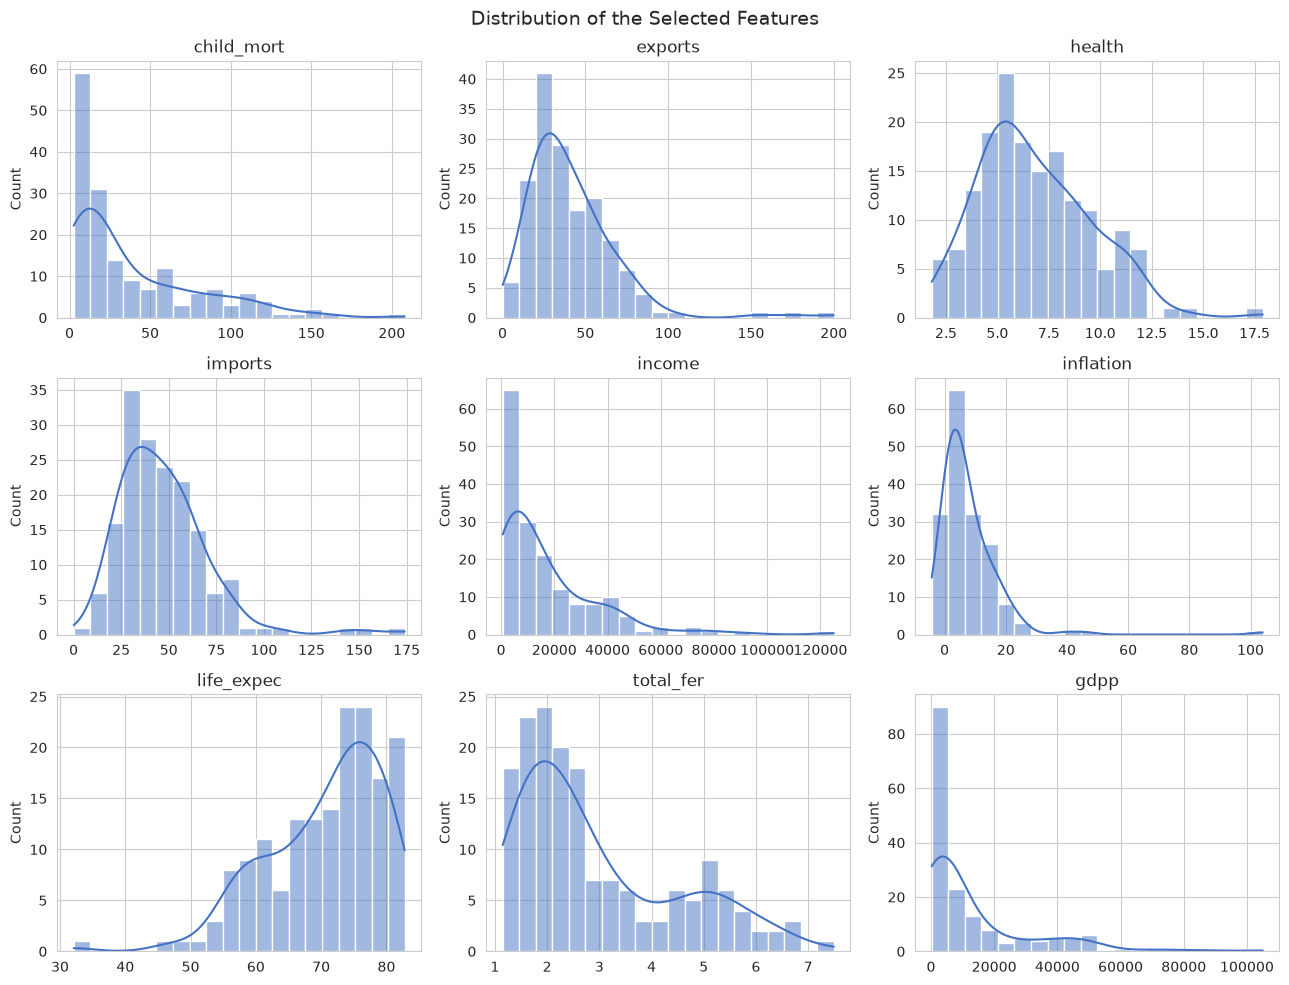

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(df[col], bins=20, kde=True, ax=ax, color='#4472C4')
    ax.set_title(col)
    ax.set_xlabel('')
plt.suptitle('Distribution of the Selected Features', fontsize=14)
plt.tight_layout()
plt.savefig('../images/histograms.png', dpi=150)
plt.show()

In [10]:
summary = pd.DataFrame({
    'mean': X.mean(),
    'median': X.median(),
    'skewness': X.skew()
}).round(2)
summary.sort_values('skewness')

,mean,median,skewness
life_expec,70.56,73.10,-0.97
health,6.82,6.32,0.71
total_fer,2.95,2.41,0.97
child_mort,38.27,19.30,1.45
imports,46.89,43.30,1.91
gdpp,12964.16,4660.00,2.22
income,17144.69,9960.00,2.23
exports,41.11,35.00,2.45
inflation,7.78,5.39,5.15


**Task 4 – Observations**

1. **Most features are right-skewed, with a few extreme countries.** `income`, `gdpp`, `child_mort`, `exports` and `inflation` have a long right tail: most countries have low values, while a few are very high. Their means are well above their medians (for example, income 17,145 vs 9,960 and GDP per capita 12,964 vs 4,660). The extremes are real countries, for example Qatar (income 125,000), Luxembourg (GDP per capita 105,000), Singapore (exports 200% of GDP) and Nigeria (inflation 104%).
2. **Life expectancy is the opposite: left-skewed.** Most countries have a life expectancy of about 70–80 years, with a short tail of low-life-expectancy countries (Haiti is lowest at 32.1). `health` and `imports` are closer to bell-shaped, with `health` the most symmetric (skewness 0.71).

Task 5: StandardScaler

In [11]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=features)

print("Mean after scaling:", X_scaled.mean(axis=0).round(3))
print("Std after scaling: ", X_scaled.std(axis=0).round(3))
X_scaled_df.head()

Mean after scaling: [-0.  0.  0.  0. -0. -0.  0.  0.  0.]
Std after scaling:  [1. 1. 1. 1. 1. 1. 1. 1. 1.]


,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,1.291532,-1.138280,0.279088,-0.082455,-0.808245,0.157336,-1.619092,1.902882,-0.679180
1,-0.538949,-0.479658,-0.097016,0.070837,-0.375369,-0.312347,0.647866,-0.859973,-0.485623
2,-0.272833,-0.099122,-0.966073,-0.641762,-0.220844,0.789274,0.670423,-0.038404,-0.465376
3,2.007808,0.775381,-1.448071,-0.165315,-0.585043,1.387054,-1.179234,2.128151,-0.516268
4,-0.695634,0.160668,-0.286894,0.497568,0.101732,-0.601749,0.704258,-0.541946,-0.041817


In [12]:
comparison = pd.DataFrame({
    'std before': X.std().round(2),
    'std after': X_scaled_df.std().round(2),
    'min before': X.min(),
    'max before': X.max(),
})
comparison

,std before,std after,min before,max before
child_mort,40.33,1.0,2.6000,208.00
exports,27.41,1.0,0.1090,200.00
health,2.75,1.0,1.8100,17.90
imports,24.21,1.0,0.0659,174.00
income,19278.07,1.0,609.0000,125000.00
inflation,10.57,1.0,-4.2100,104.00
life_expec,8.89,1.0,32.1000,82.80
total_fer,1.51,1.0,1.1500,7.49
gdpp,18328.70,1.0,231.0000,105000.00


**Task 5 – Why feature scaling is required for K-Means**

K-Means assigns each country to the nearest cluster centre using Euclidean distance, so features with large numeric ranges dominate the distance. Here `income` (609 – 125,000) and `gdpp` (231 – 105,000) are thousands of times larger than `health` (1.81 – 17.9) or `total_fer` (1.15 – 7.49). Without scaling, the clusters would be decided almost only by income and GDP per capita, and life expectancy, child mortality and fertility would have almost no influence.

`StandardScaler` transforms each feature to mean 0 and standard deviation 1 (z = (x − mean) / std), so all nine features contribute equally to the distance. The scaled data (`X_scaled`) is used for the Elbow Method, the Silhouette Score and the final K-Means model.

Task 6: Elbow Method

In [13]:
k_range = range(1, 11)
inertias = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

elbow_df = pd.DataFrame({'K': list(k_range), 'Inertia (SSE)': inertias})
elbow_df['Drop from previous K'] = elbow_df['Inertia (SSE)'].diff().abs()
elbow_df.round(2)

,K,Inertia (SSE),Drop from previous K
0,1,1503.00,NaN
1,2,1050.21,452.79
2,3,831.42,218.79
3,4,700.52,130.90
4,5,620.16,80.36
5,6,558.47,61.69
6,7,495.81,62.66
7,8,457.59,38.22
8,9,427.80,29.78
9,10,403.23,24.57


Task 7: Sillhouette Method

In [14]:
sil_scores = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_scaled)
    sil_scores.append(silhouette_score(X_scaled, labels))

sil_df = pd.DataFrame({'K': range(2, 11), 'Silhouette score': sil_scores})
best_k = int(sil_df.loc[sil_df['Silhouette score'].idxmax(), 'K'])

print("K with the best Silhouette Score:", best_k)
sil_df.round(4)

K with the best Silhouette Score: 5


,K,Silhouette score
0,2,0.2874
1,3,0.2833
2,4,0.2960
3,5,0.2993
4,6,0.2287
5,7,0.2477
6,8,0.2388
7,9,0.2073
8,10,0.2022


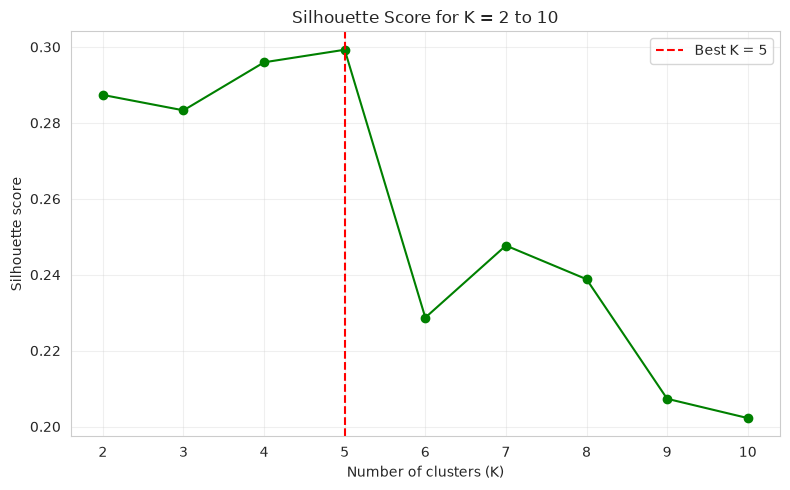

In [15]:
plt.figure(figsize=(8, 5))
plt.plot(sil_df['K'], sil_df['Silhouette score'], 'o-', color='green')
plt.axvline(best_k, color='red', linestyle='--', label=f'Best K = {best_k}')
plt.xticks(range(2, 11))
plt.xlabel('Number of clusters (K)')
plt.ylabel('Silhouette score')
plt.title('Silhouette Score for K = 2 to 10')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../images/silhouette.png', dpi=150)
plt.show()

In [16]:
for k in [3, 4, 5]:
    labels = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(X_scaled)
    print(f"K={k}: cluster sizes =", np.bincount(labels))

K=3: cluster sizes = [36 47 84]
K=4: cluster sizes = [32 47 85  3]
K=5: cluster sizes = [84 47  3 32  1]


**Tasks 6–7 findings**

- **Elbow:** inertia falls from 1503 (K=1) to 403 (K=10). The largest drops are K=1→2 and K=2→3; after K≈4 the gains are small, so the elbow is gradual and suggests K between 3 and 5.
- **Silhouette:** the best score is at **K = 5 (0.2993)**, but all scores for K = 2–5 are between 0.28 and 0.30, so the cluster structure is weak and the differences are small.
- K = 5 isolates the 3 trade hubs (Luxembourg, Malta, Singapore) and Nigeria (extreme inflation) as tiny clusters, which are outliers and not development segments. **K = 3** has a near-best silhouette (0.2833), sits at the elbow, and gives three balanced, interpretable groups (36 / 47 / 84 countries), so it is used for the final model.

Task 8: final K-Means model

In [17]:
final_k = 3   # selected K (change here if you decide on a different value)

kmeans = KMeans(n_clusters=final_k, random_state=RANDOM_STATE, n_init=10)
kmeans.fit(X_scaled)

print("Selected K:", final_k)
print("Inertia (SSE):", round(kmeans.inertia_, 2))
print("Silhouette score:", round(silhouette_score(X_scaled, kmeans.labels_), 4))

Selected K: 3
Inertia (SSE): 831.42
Silhouette score: 0.2833


Task 9: add the Cluster column

In [18]:
df['Cluster'] = kmeans.labels_

print(df['Cluster'].value_counts().sort_index())
df.head()

Cluster
0    36
1    47
2    84
Name: count, dtype: int64


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,Cluster
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553,1
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090,2
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460,2
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530,1
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200,2


Task 10: cluster scatter plot

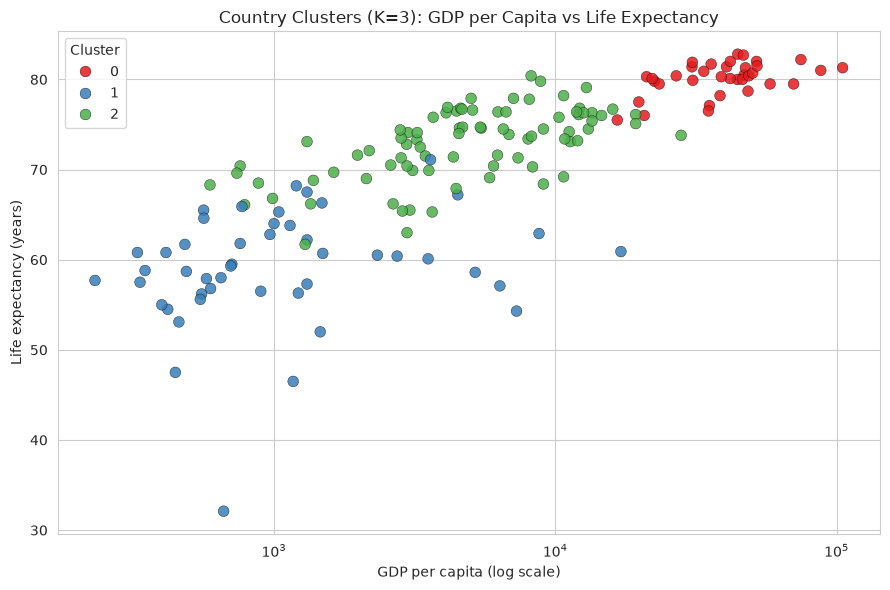

In [19]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='gdpp', y='life_expec', hue='Cluster',
                palette='Set1', s=60, alpha=0.85, edgecolor='k', linewidth=0.3)
plt.xscale('log')
plt.xlabel('GDP per capita (log scale)')
plt.ylabel('Life expectancy (years)')
plt.title(f'Country Clusters (K={final_k}): GDP per Capita vs Life Expectancy')
plt.tight_layout()
plt.savefig('../images/cluster_scatter.png', dpi=150)
plt.show()

Task 11: cluster summary table

In [20]:
cluster_summary = df.groupby('Cluster')[features].mean().round(2)
cluster_summary['countries'] = df.groupby('Cluster').size()
cluster_summary

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,countries
Cluster,,,,,,,,,,
0,5.00,58.74,8.81,51.49,45672.22,2.67,80.13,1.75,42494.44,36
1,92.96,29.15,6.39,42.32,3942.40,12.02,59.19,5.01,1922.38,47
2,21.93,40.24,6.20,47.47,12305.60,7.60,72.81,2.31,6486.45,84


Task 12: naming clusters

In [21]:
order = cluster_summary['gdpp'].sort_values().index.tolist()   # lowest -> highest
cluster_names = {
    order[0]: 'Low-development countries',
    order[1]: 'Developing countries',
    order[2]: 'High-income developed countries'
}
df['Cluster_Name'] = df['Cluster'].map(cluster_names)

named_summary = cluster_summary.rename(index=cluster_names)
named_summary

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,countries
Cluster,,,,,,,,,,
High-income developed countries,5.00,58.74,8.81,51.49,45672.22,2.67,80.13,1.75,42494.44,36
Low-development countries,92.96,29.15,6.39,42.32,3942.40,12.02,59.19,5.01,1922.38,47
Developing countries,21.93,40.24,6.20,47.47,12305.60,7.60,72.81,2.31,6486.45,84


In [22]:
# Example countries in each cluster (5 with the highest GDP per capita)
for name in cluster_names.values():
    members = df[df['Cluster_Name'] == name].sort_values('gdpp', ascending=False)
    print(f"{name} ({len(members)}): {', '.join(members['country'].head(5))}")

Low-development countries (47): Equatorial Guinea, Gabon, South Africa, Botswana, Namibia
Developing countries (84): Bahamas, Saudi Arabia, Oman, Barbados, Estonia
High-income developed countries (36): Luxembourg, Norway, Switzerland, Qatar, Denmark


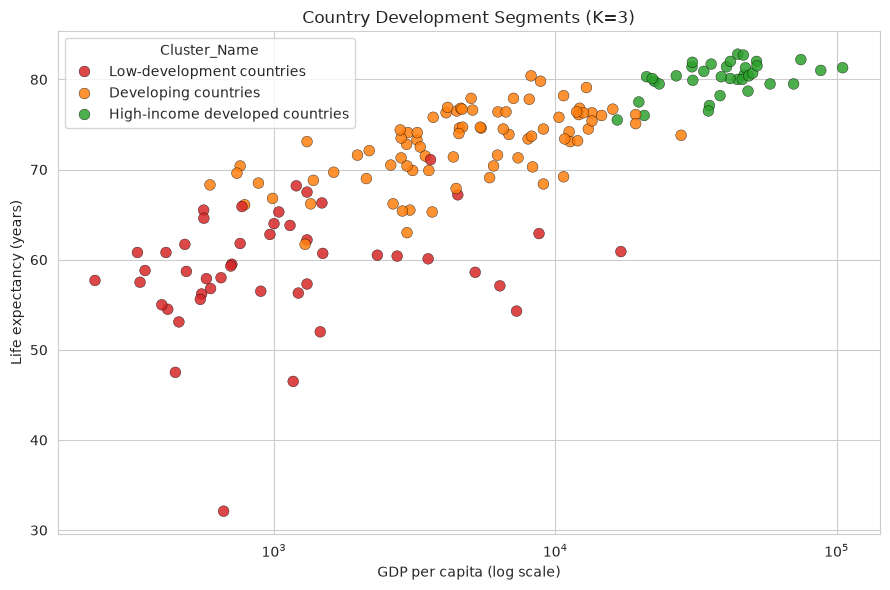

In [23]:
# Scatter plot with the cluster names
palette = {'Low-development countries': '#d62728',
           'Developing countries': '#ff7f0e',
           'High-income developed countries': '#2ca02c'}

plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='gdpp', y='life_expec', hue='Cluster_Name',
                hue_order=list(palette), palette=palette,
                s=60, alpha=0.85, edgecolor='k', linewidth=0.3)
plt.xscale('log')
plt.xlabel('GDP per capita (log scale)')
plt.ylabel('Life expectancy (years)')
plt.title('Country Development Segments (K=3)')
plt.tight_layout()
plt.savefig('../images/cluster_scatter_named.png', dpi=150)
plt.show()

## Task 12 – Cluster interpretation

| Cluster | Name | Countries | What the summary shows |
|---|---|---|---|
| 0 | **High-income developed countries** | 36 | Very low child mortality (5.0), highest income (45,672) and GDP per capita (42,494), life expectancy 80.1, low fertility (1.75), low inflation (2.7%), highest health spending (8.8% of GDP) and the most trade-open economies (exports 58.7%, imports 51.5% of GDP). |
| 2 | **Developing countries** | 84 | Mid-range on every indicator: child mortality 21.9, income 12,306, GDP per capita 6,486, life expectancy 72.8, fertility 2.3, inflation 7.6%. |
| 1 | **Low-development countries** | 47 | Very high child mortality (93.0), lowest income (3,942) and GDP per capita (1,922), life expectancy only 59.2, high fertility (5.0 children per woman) and the highest inflation (12.0%). |

Bangladesh falls in the Developing group.